[RoPE 124.84M baseline] last 0.1B tokens [2.9015, 3.0015]B (62 pts), avg loss = 3.119470
[ConvPE 128.13M] last 0.1B tokens [2.9015, 3.0015]B (62 pts), avg loss = 3.031643


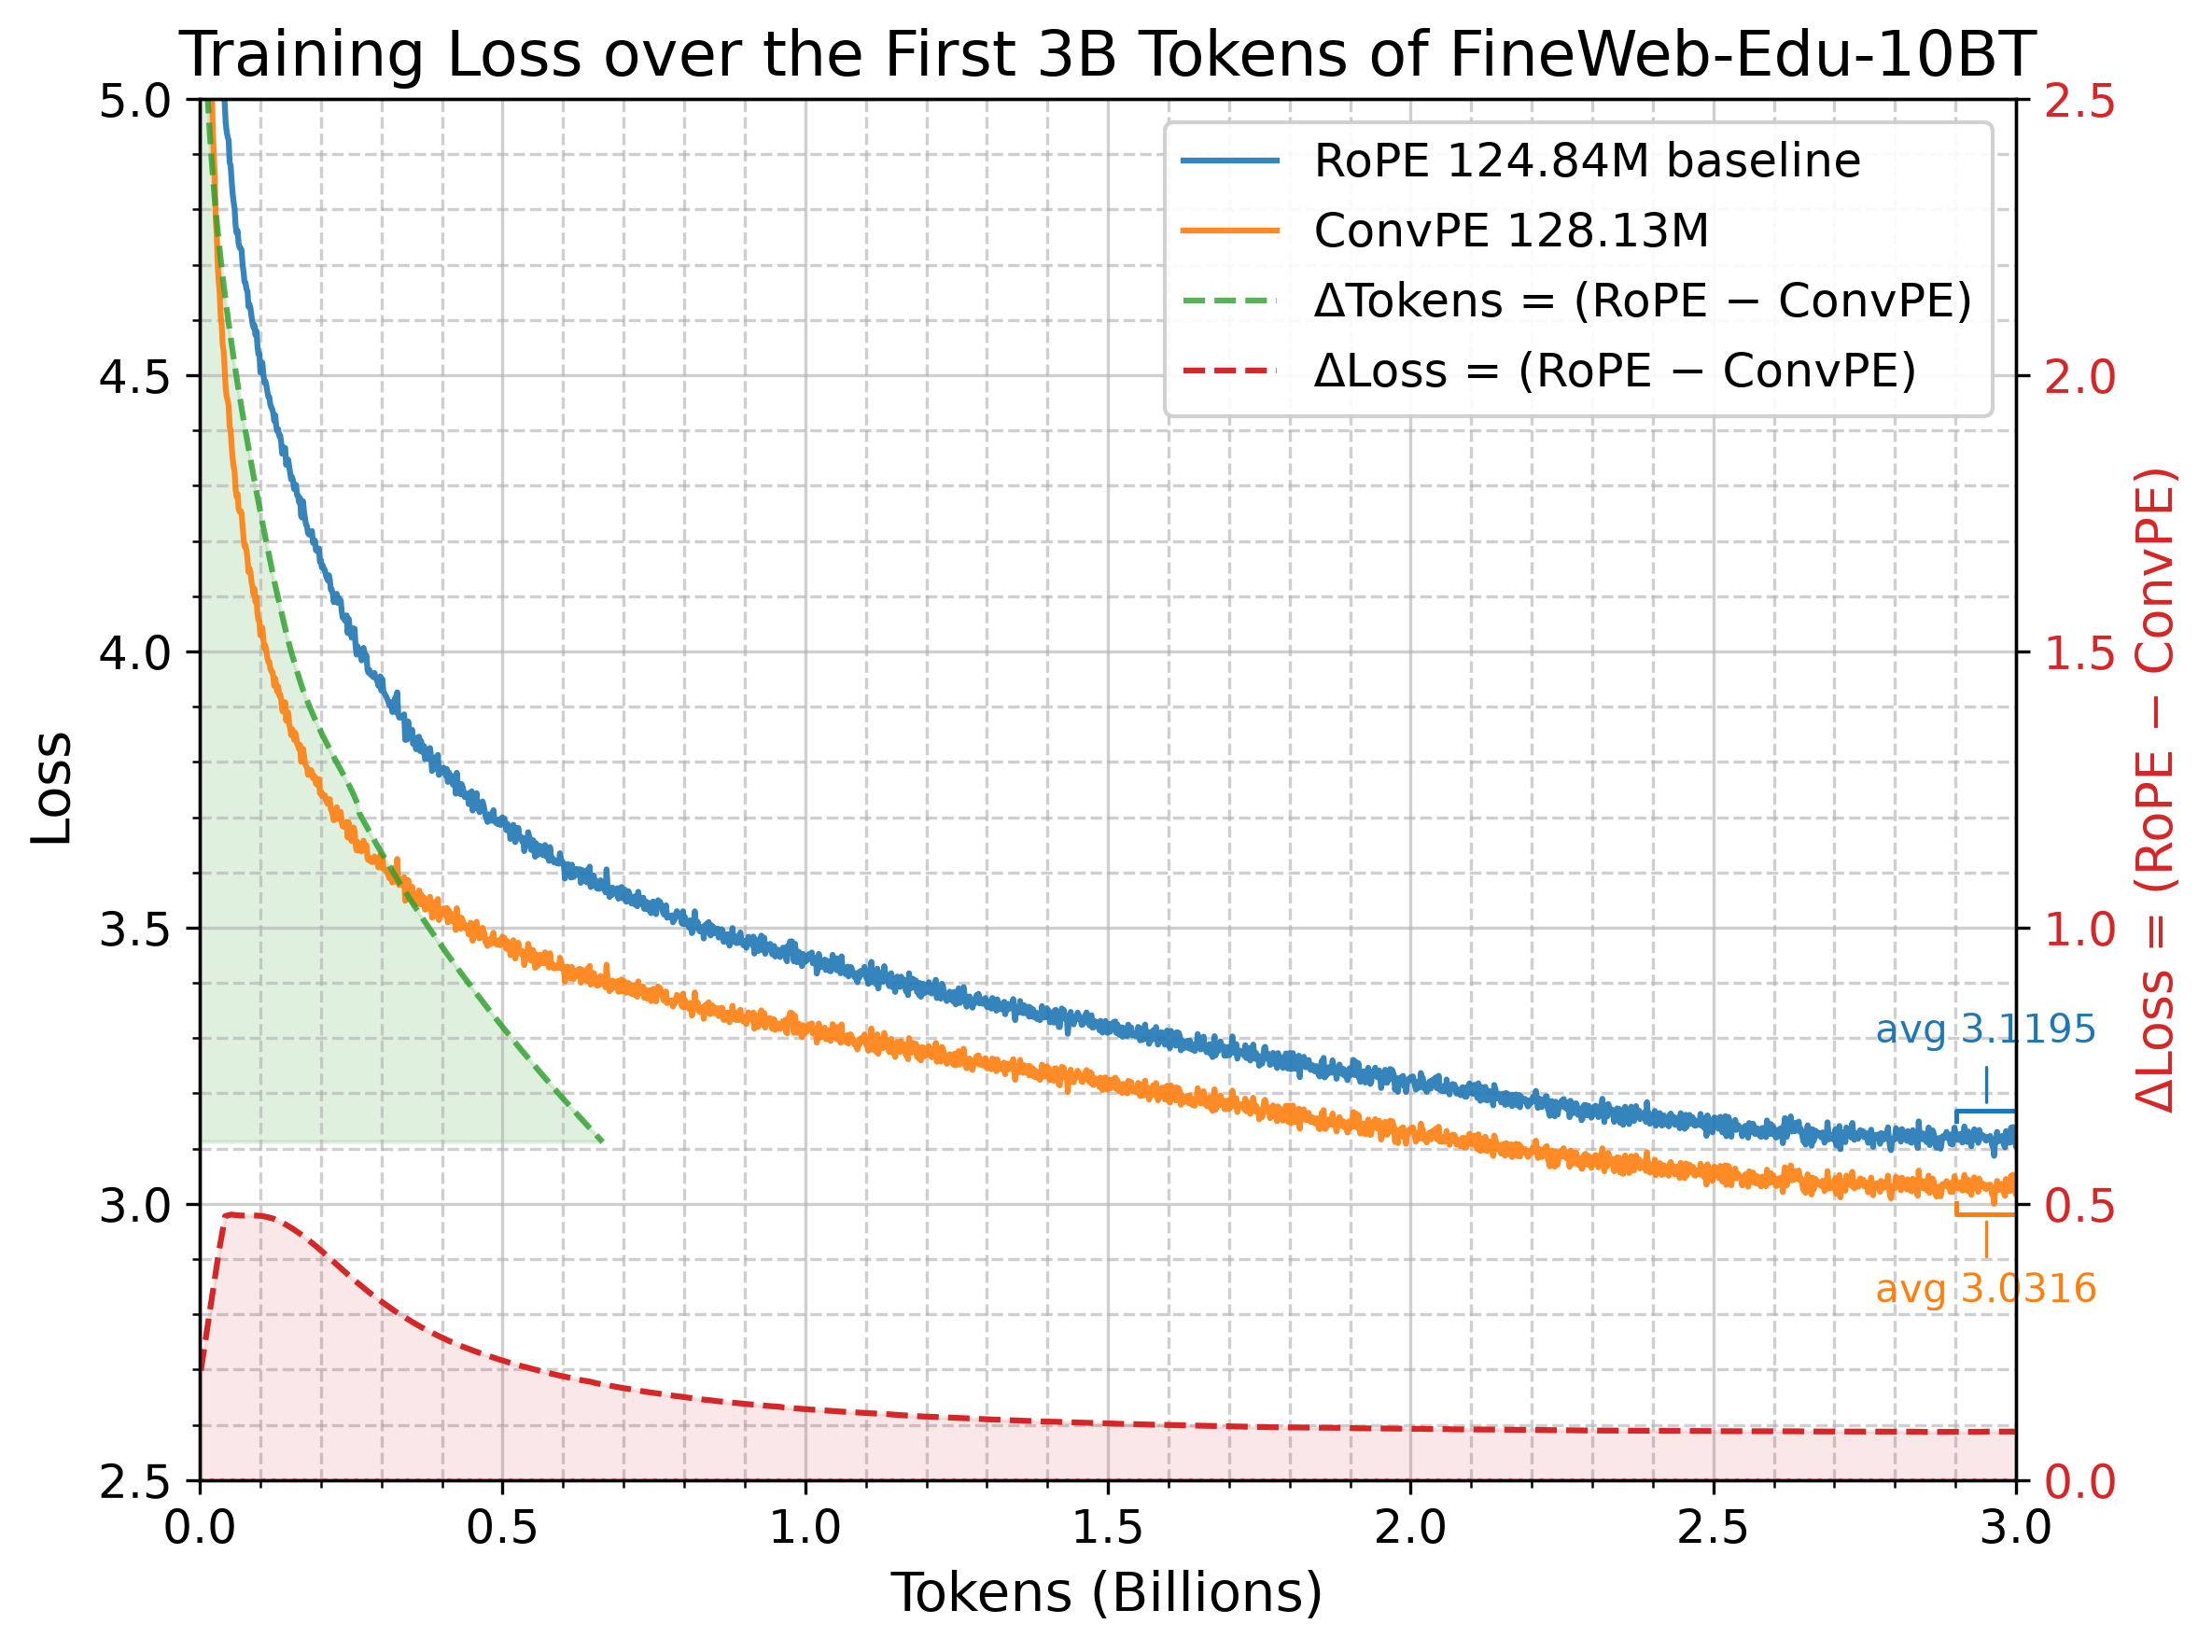

In [70]:
import os, re
import json
import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.interpolate import PchipInterpolator
    from scipy.signal import savgol_filter
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False

# ========= 填入你的文件夹列表 =========
FOLDERS = [
    "results_pretrain/base_rope_42",
    "results_pretrain/base_nope_w128d16r0h1g1_42",
]

TOKENS_PER_STEP = 16 * 1024
TOKENS_PER_BILLION = 1e9


def name_to_label(name):
    parts = name.split("_")
    name = " ".join(parts[0:-1])
    return {
        "base rope": "RoPE 124.84M baseline",
        "base nope w128d16r0h1g1": "ConvPE 128.13M",
    }.get(name, name)


def read_trainer_state(ckpt_dir):
    path = os.path.join(ckpt_dir, "trainer_state.json")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        return json.load(f)


# ---------- 平滑工具 ----------
def _odd_int(w):
    w = int(w)
    return w if w % 2 == 1 else w + 1


def moving_average(y, window):
    window = _odd_int(window)
    if window <= 1 or window >= len(y):
        return y.copy()
    pad = window // 2
    y_pad = np.pad(y, pad, mode="edge")
    kernel = np.ones(window) / window
    return np.convolve(y_pad, kernel, mode="valid")


def monotonic_tokens_vs_loss(tokens, losses, smooth_window):
    losses_s = moving_average(losses, smooth_window)
    losses_m = np.minimum.accumulate(losses_s)
    out_t, out_l = [], []
    i, n = 0, len(losses_m)
    while i < n:
        j = i
        while j + 1 < n and losses_m[j + 1] == losses_m[i]:
            j += 1
        out_t.append(float(np.median(tokens[i:j + 1])))
        out_l.append(float(losses_m[i]))
        i = j + 1
    return np.array(out_t), np.array(out_l)


# ---------- 读数据 ----------
data_store = {}

for folder in FOLDERS:
    folder = folder.rstrip("/")
    name = os.path.basename(folder)
    label = name_to_label(name)
    if not os.path.isdir(folder):
        continue

    ckpts = sorted(
        (int(m.group(1)), d)
        for d in os.listdir(folder)
        if (m := re.fullmatch(r"checkpoint-(\d+)", d))
        and os.path.isdir(os.path.join(folder, d))
    )
    if not ckpts:
        continue

    state = read_trainer_state(os.path.join(folder, ckpts[-1][1]))
    if not state:
        continue

    train_pts = sorted(
        (e["step"] * TOKENS_PER_STEP / TOKENS_PER_BILLION, e["loss"])
        for e in state.get("log_history", [])
        if "loss" in e and "eval_loss" not in e and "step" in e
    )
    if not train_pts:
        continue

    data_store[label] = np.array(train_pts)

if len(data_store) < 2:
    print("未能读取到两个模型的数据，请检查路径。")
    exit()

keys = list(data_store.keys())
tokens_rope, losses_rope = data_store[keys[0]][:, 0], data_store[keys[0]][:, 1]
tokens_conv, losses_conv = data_store[keys[1]][:, 0], data_store[keys[1]][:, 1]


# ---------- 最后 0.1B tokens 的平均 loss（原始日志点，不做平滑）----------
def avg_loss_last_span(tokens, losses, span_b=0.1):
    """取 tokens 落在 [max(tokens)-span_b, max(tokens)] 的原始 loss 点求均值。"""
    end = float(tokens.max())
    start = max(0.0, end - span_b)
    mask = tokens >= start
    if not mask.any():
        mask = np.zeros_like(tokens, dtype=bool)
        mask[-1] = True
    return float(losses[mask].mean()), start, end, int(mask.sum())


avg_rope_last, start_rope_last, end_rope_last, n_rope_last = avg_loss_last_span(
    tokens_rope, losses_rope, span_b=0.1
)
avg_conv_last, start_conv_last, end_conv_last, n_conv_last = avg_loss_last_span(
    tokens_conv, losses_conv, span_b=0.1
)

print(f"[{keys[0]}] last 0.1B tokens "
      f"[{start_rope_last:.4f}, {end_rope_last:.4f}]B "
      f"({n_rope_last} pts), avg loss = {avg_rope_last:.6f}")
print(f"[{keys[1]}] last 0.1B tokens "
      f"[{start_conv_last:.4f}, {end_conv_last:.4f}]B "
      f"({n_conv_last} pts), avg loss = {avg_conv_last:.6f}")


# ---------- 平滑 + 单调化 ----------
win_rope = _odd_int(max(5, len(losses_rope) // 50))
win_conv = _odd_int(max(5, len(losses_conv) // 50))

tokens_rope_u, loss_rope_u = monotonic_tokens_vs_loss(tokens_rope, losses_rope, win_rope)
tokens_conv_u, loss_conv_u = monotonic_tokens_vs_loss(tokens_conv, losses_conv, win_conv)

min_loss = max(loss_rope_u.min(), loss_conv_u.min())
max_loss = min(loss_rope_u.max(), loss_conv_u.max())
target_losses = np.linspace(max_loss, min_loss, 300)


def interp_tokens_from_loss(loss_u, tokens_u, target):
    xp = loss_u[::-1]
    fp = tokens_u[::-1]
    if HAS_SCIPY:
        return PchipInterpolator(xp, fp)(target)
    return np.interp(target, xp, fp)


tokens_rope_interp = interp_tokens_from_loss(loss_rope_u, tokens_rope_u, target_losses)
tokens_conv_interp = interp_tokens_from_loss(loss_conv_u, tokens_conv_u, target_losses)

delta_tokens_raw = tokens_rope_interp - tokens_conv_interp

if HAS_SCIPY and len(delta_tokens_raw) > 11:
    w = _odd_int(min(101, max(11, len(delta_tokens_raw) // 4)))
    delta_tokens = savgol_filter(delta_tokens_raw, window_length=w, polyorder=3)
else:
    delta_tokens = moving_average(delta_tokens_raw, max(3, len(delta_tokens_raw) // 20))

# ================= ΔLoss = RoPE − ConvPE（不平滑） =================
t_lo = max(tokens_rope_u.min(), tokens_conv_u.min())
t_hi = min(tokens_rope_u.max(), tokens_conv_u.max())

if t_hi > t_lo:
    target_tokens = np.linspace(t_lo, t_hi, 300)

    def interp_loss_from_tokens(tokens_u, loss_u, target):
        if HAS_SCIPY:
            return PchipInterpolator(tokens_u, loss_u)(target)
        return np.interp(target, tokens_u, loss_u)

    loss_rope_t = interp_loss_from_tokens(tokens_rope_u, loss_rope_u, target_tokens)
    loss_conv_t = interp_loss_from_tokens(tokens_conv_u, loss_conv_u, target_tokens)

    delta_loss = loss_rope_t - loss_conv_t
else:
    target_tokens, delta_loss = None, None

# ================= 绘图 =================
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

color_rope = "tab:blue"
color_conv = "tab:orange"
color_green = "tab:green"
color_dloss = "tab:red"

line1, = ax.plot(tokens_rope, losses_rope, alpha=0.9, color=color_rope, label=keys[0])
line2, = ax.plot(tokens_conv, losses_conv, alpha=0.9, color=color_conv, label=keys[1])

line3, = ax.plot(delta_tokens, target_losses, alpha=0.8, linestyle="--", color=color_green,
                 label="ΔTokens = (RoPE − ConvPE)")
ax.fill_betweenx(target_losses, 0, delta_tokens, color=color_green, alpha=0.15)

ax.set_xlabel("Tokens (Billions)", fontsize=14)
ax.set_ylabel("Loss", fontsize=14)
ax.set_ylim(2.5, 5.0)
ax.set_xlim(0, 3)
ax.tick_params(axis='both', labelsize=12)
ax.minorticks_on()
ax.grid(True, which='major', linestyle='-', alpha=0.6)
ax.grid(True, which='minor', linestyle='--', alpha=0.6)
ax.set_title("Training Loss over the First 3B Tokens of FineWeb-Edu-10BT", fontsize=16)


# ---------- 标注：最后 0.1B 平均 loss（水平方括号 + 上下引线）----------
def draw_horizontal_bracket(ax, x_start, x_end, y, color, text, y_dir, hook_height=0.02, text_offset=15):
    """绘制水平括号，y_dir=1 为上方（开口向下），-1 为下方（开口向上）。"""
    y_b = y + y_dir * 0.05  # 括号距离平均线的垂直偏移
    # 画水平方括号（三个线段形成 ┌───┐ 或 └───┘）
    ax.plot([x_start, x_start, x_end, x_end], 
            [y_b - y_dir * hook_height, y_b, y_b, y_b - y_dir * hook_height], 
            color=color, lw=1.2)
    
    # 引线 + 文字
    x_mid = (x_start + x_end) / 2
    ax.annotate(
        text,
        xy=(x_mid, y_b),
        xytext=(0, y_dir * text_offset),
        textcoords="offset points",
        color=color,
        fontsize=10,
        ha="center",
        va="bottom" if y_dir > 0 else "top",
        arrowprops=dict(arrowstyle="-", color=color, lw=0.8),
        annotation_clip=False
    )

# 标注 RoPE（引到上方）
draw_horizontal_bracket(
    ax, start_rope_last, end_rope_last, avg_rope_last,
    color=color_rope, text=f"avg {avg_rope_last:.4f}", y_dir=1
)

# 标注 ConvPE（引到下方）
draw_horizontal_bracket(
    ax, start_conv_last, end_conv_last, avg_conv_last,
    color=color_conv, text=f"avg {avg_conv_last:.4f}", y_dir=-1
)


# ---------- 右轴：ΔLoss = RoPE − ConvPE，以 2.5 为 0 点 ----------
BASE = 2.5
DLOSS_SCALE = 1.0    # 想放大 ΔLoss 波动可设 10、100（刻度会自动换算）

extra_lines = []
if delta_loss is not None:
    ax2 = ax.twinx()
    ax2.set_ylim(BASE, 5.0)

    y_plot = BASE + DLOSS_SCALE * delta_loss
    line4, = ax2.plot(target_tokens, y_plot, color=color_dloss,
                      linestyle="--", label="ΔLoss = (RoPE − ConvPE)")
    ax2.axhline(BASE, color=color_dloss, lw=1, linestyle=":", alpha=0.6)
    ax2.fill_between(target_tokens, BASE, y_plot, color=color_dloss, alpha=0.10)

    yticks = np.arange(BASE, 5.01, 0.5)
    ax2.set_yticks(yticks)
    ax2.set_yticklabels([f"{(t - BASE) / DLOSS_SCALE:.1f}" for t in yticks])
    ax2.tick_params(axis='y', labelcolor=color_dloss, labelsize=12)
    ax2.set_ylabel("ΔLoss = (RoPE − ConvPE)", fontsize=13, color=color_dloss)

    extra_lines.append(line4)

# ---------- 图例合并 ----------
lines = [line1, line2, line3] + extra_lines
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc="upper right",
          fontsize=12, title_fontsize=13, framealpha=0.9)

fig.tight_layout()
plt.show()

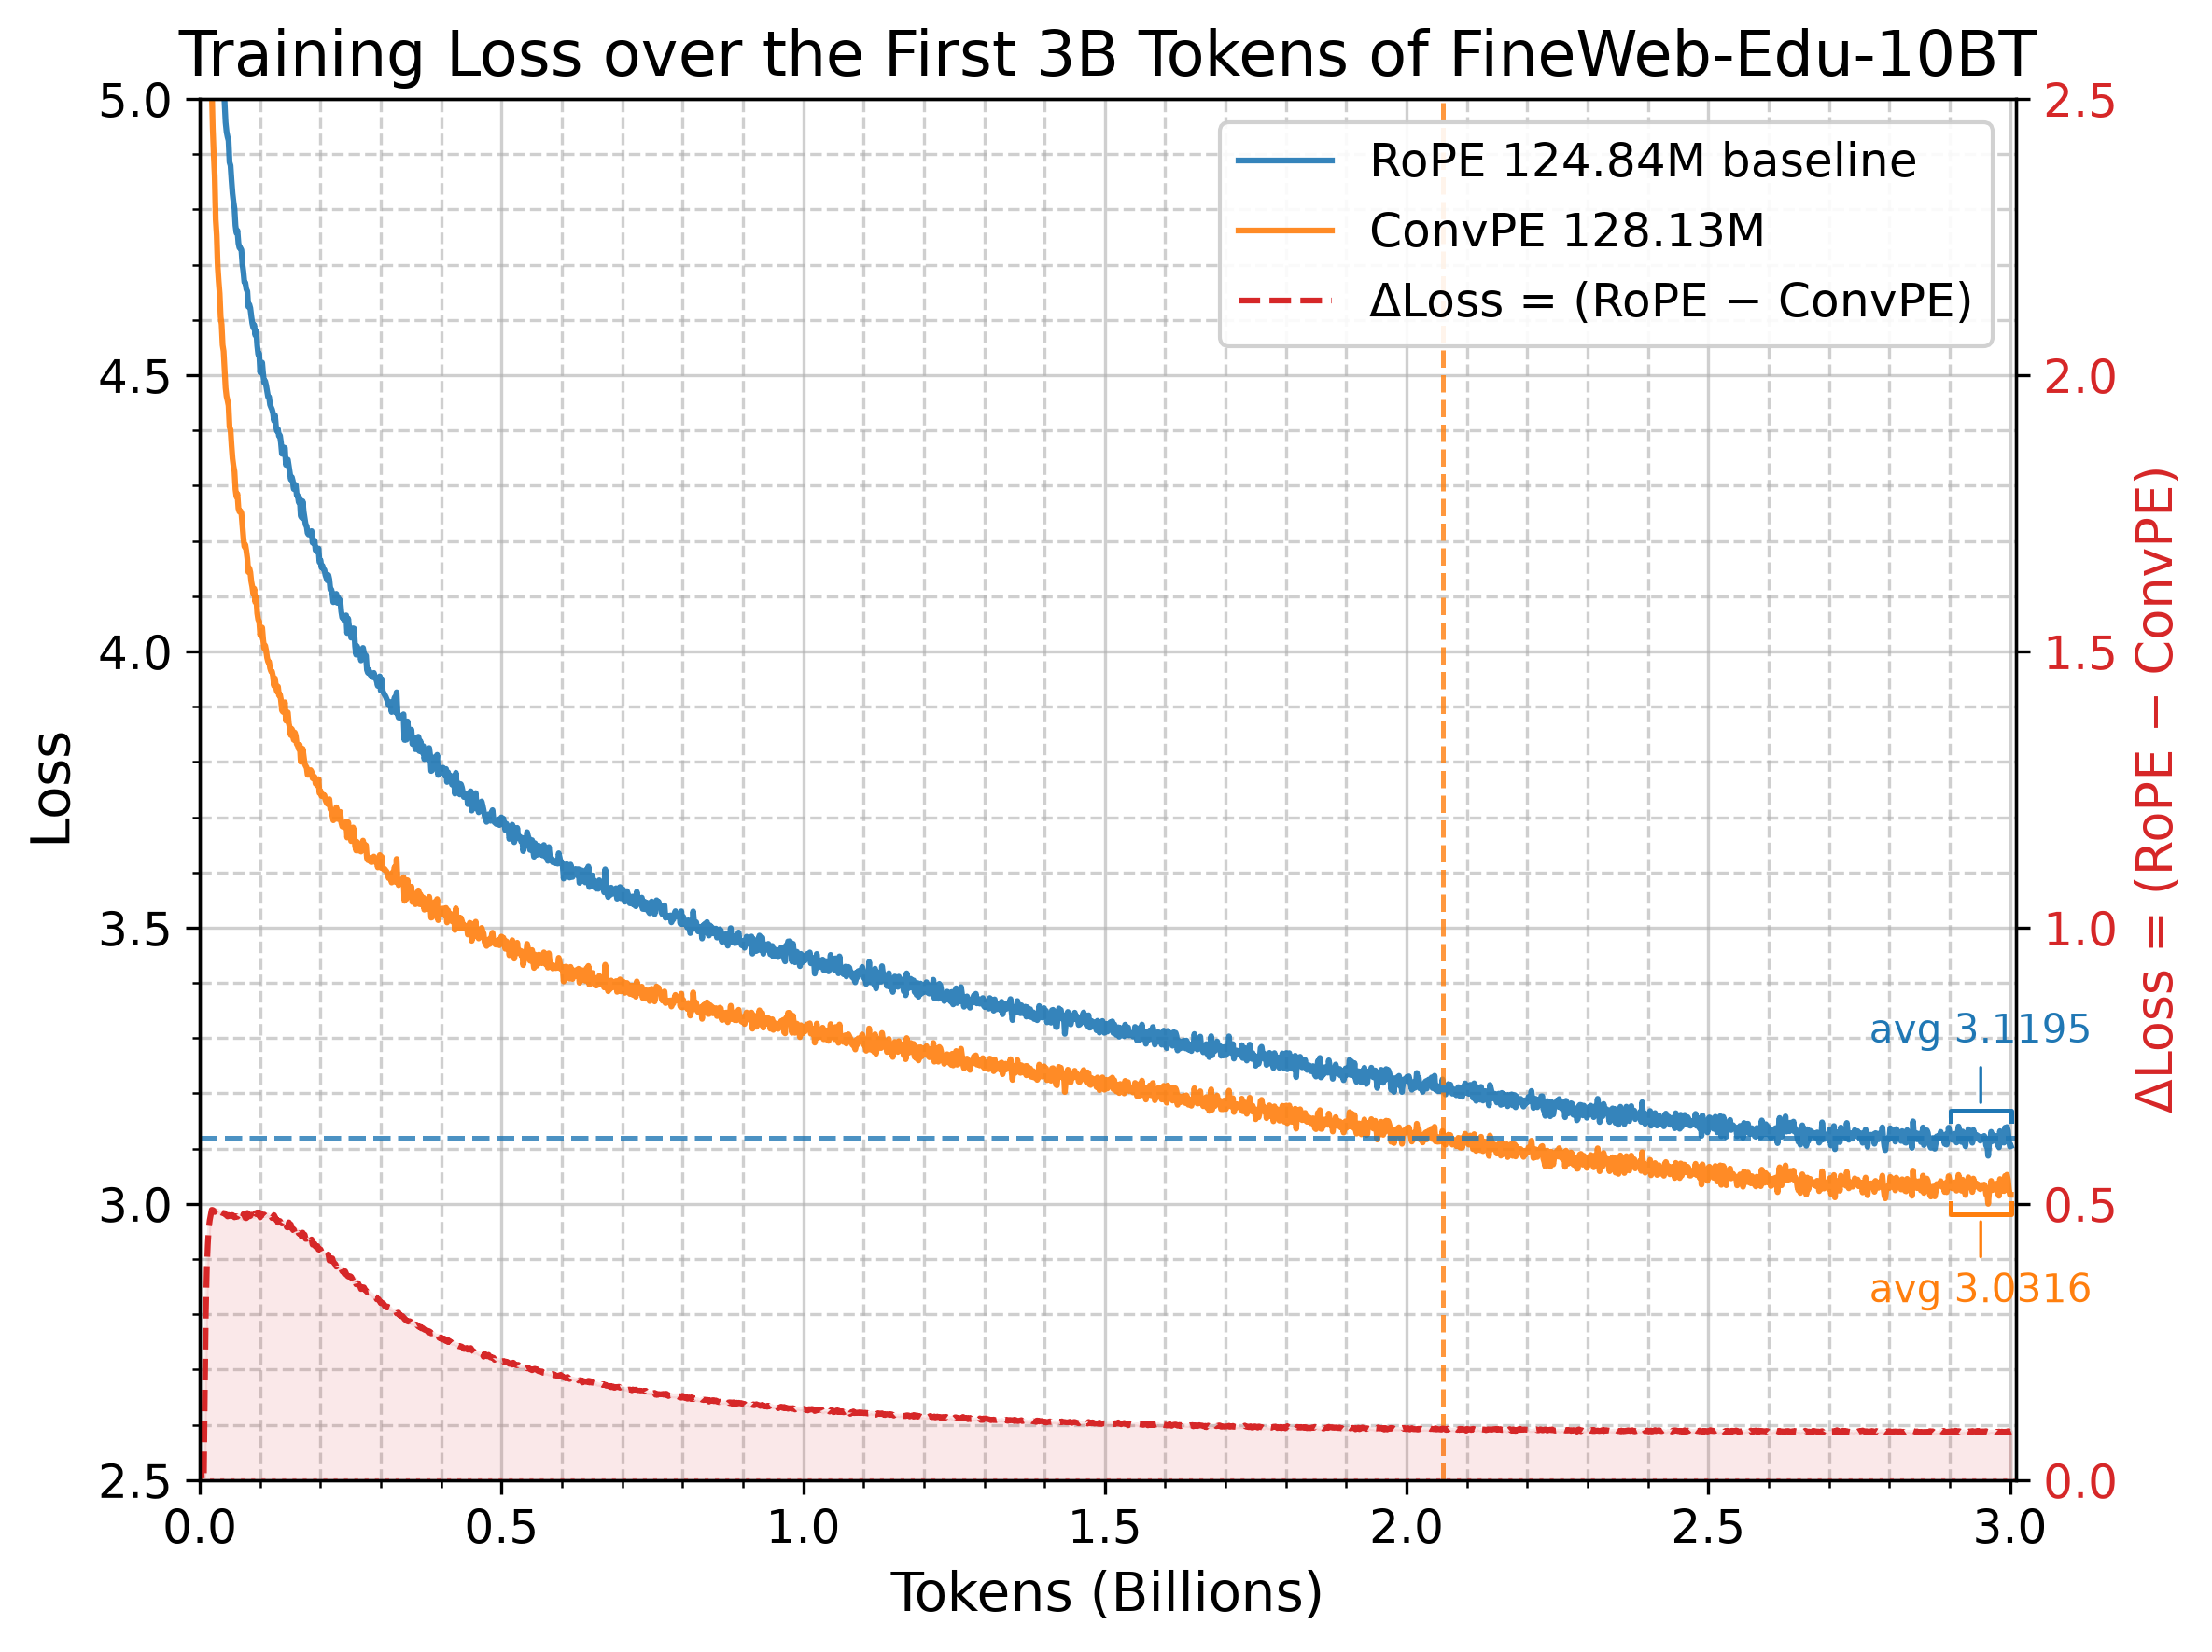

In [72]:
import os, re
import json
import numpy as np
import matplotlib.pyplot as plt

# ========= 填入你的文件夹列表 =========
FOLDERS = [
    "results_pretrain/base_rope_42",
    "results_pretrain/base_nope_w128d16r0h1g1_42",
]

TOKENS_PER_STEP = 16 * 1024
TOKENS_PER_BILLION = 1e9


def name_to_label(name):
    parts = name.split("_")
    name = " ".join(parts[0:-1])
    return {
        "base rope": "RoPE 124.84M baseline",
        "base nope w128d16r0h1g1": "ConvPE 128.13M",
    }.get(name, name)


def read_trainer_state(ckpt_dir):
    path = os.path.join(ckpt_dir, "trainer_state.json")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        return json.load(f)


# ---------- 读数据 ----------
data_store = {}

for folder in FOLDERS:
    folder = folder.rstrip("/")
    name = os.path.basename(folder)
    label = name_to_label(name)
    if not os.path.isdir(folder):
        continue

    ckpts = sorted(
        (int(m.group(1)), d)
        for d in os.listdir(folder)
        if (m := re.fullmatch(r"checkpoint-(\d+)", d))
        and os.path.isdir(os.path.join(folder, d))
    )
    if not ckpts:
        continue

    state = read_trainer_state(os.path.join(folder, ckpts[-1][1]))
    if not state:
        continue

    train_data = sorted(
        (e["step"], e["loss"])
        for e in state.get("log_history", [])
        if "loss" in e and "eval_loss" not in e and "step" in e
    )
    if not train_data:
        continue

    steps = np.array([x[0] for x in train_data])
    losses = np.array([x[1] for x in train_data])
    tokens = steps * TOKENS_PER_STEP / TOKENS_PER_BILLION

    data_store[label] = {"steps": steps, "tokens": tokens, "losses": losses}

if len(data_store) < 2:
    print("未能读取到两个模型的数据，请检查路径。")
    exit()

keys = list(data_store.keys())
model_rope = data_store[keys[0]]
model_conv = data_store[keys[1]]


# ---------- 最后 0.1B tokens 的平均 loss ----------
def avg_loss_last_span(tokens, losses, span_b=0.1):
    end = float(tokens.max())
    start = max(0.0, end - span_b)
    mask = tokens >= start
    if not mask.any():
        mask = np.zeros_like(tokens, dtype=bool)
        mask[-1] = True
    return float(losses[mask].mean()), start, end, int(mask.sum())


avg_rope_last, start_rope_last, end_rope_last, _ = avg_loss_last_span(
    model_rope["tokens"], model_rope["losses"], span_b=0.1
)
avg_conv_last, start_conv_last, end_conv_last, _ = avg_loss_last_span(
    model_conv["tokens"], model_conv["losses"], span_b=0.1
)


# ---------- 对齐同 Step 计算 ΔLoss ----------
common_steps, idx_rope, idx_conv = np.intersect1d(
    model_rope["steps"], model_conv["steps"], return_indices=True
)

aligned_loss_rope = model_rope["losses"][idx_rope]
aligned_loss_conv = model_conv["losses"][idx_conv]
delta_loss = aligned_loss_rope - aligned_loss_conv

tokens_common = common_steps * TOKENS_PER_STEP / TOKENS_PER_BILLION


# ================= 绘图 =================
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

color_rope = "tab:blue"
color_conv = "tab:orange"
color_dloss = "tab:red"

(line1,) = ax.plot(
    model_rope["tokens"],
    model_rope["losses"],
    alpha=0.9,
    color=color_rope,
    label=keys[0],
)
(line2,) = ax.plot(
    model_conv["tokens"],
    model_conv["losses"],
    alpha=0.9,
    color=color_conv,
    label=keys[1],
)

# ===== 新增：贯穿全图的蓝色平均 loss 水平线 =====
line_rope_avg = ax.axhline(
    avg_rope_last,
    color=color_rope,
    linestyle="--",
    lw=1.2,
    alpha=0.8,
)

line_rope_avg = ax.axvline(
    2.06,
    color=color_conv,
    linestyle="--",
    lw=1.2,
    alpha=0.8,
)

ax.set_xlabel("Tokens (Billions)", fontsize=14)
ax.set_ylabel("Loss", fontsize=14)
ax.set_ylim(2.5, 5.0)
ax.set_xlim(0, 3.01)
ax.tick_params(axis="both", labelsize=12)
ax.minorticks_on()
ax.grid(True, which="major", linestyle="-", alpha=0.6)
ax.grid(True, which="minor", linestyle="--", alpha=0.6)
ax.set_title("Training Loss over the First 3B Tokens of FineWeb-Edu-10BT", fontsize=16)


# ---------- 最后 0.1B 平均 loss 标注（仅保留横向方括号+文字） ----------
def draw_horizontal_bracket(
    ax, x_start, x_end, y, color, text, y_dir, hook_height=0.02, text_offset=15
):
    y_b = y + y_dir * 0.05
    ax.plot(
        [x_start, x_start, x_end, x_end],
        [y_b - y_dir * hook_height, y_b, y_b, y_b - y_dir * hook_height],
        color=color,
        lw=1.2,
    )
    x_mid = (x_start + x_end) / 2
    ax.annotate(
        text,
        xy=(x_mid, y_b),
        xytext=(0, y_dir * text_offset),
        textcoords="offset points",
        color=color,
        fontsize=10,
        ha="center",
        va="bottom" if y_dir > 0 else "top",
        arrowprops=dict(arrowstyle="-", color=color, lw=0.8),
        annotation_clip=False,
    )


draw_horizontal_bracket(
    ax,
    start_rope_last,
    end_rope_last,
    avg_rope_last,
    color=color_rope,
    text=f"avg {avg_rope_last:.4f}",
    y_dir=1,
)
draw_horizontal_bracket(
    ax,
    start_conv_last,
    end_conv_last,
    avg_conv_last,
    color=color_conv,
    text=f"avg {avg_conv_last:.4f}",
    y_dir=-1,
)


# ---------- 右轴：ΔLoss (同 Step 减法) ----------
BASE = 2.5
DLOSS_SCALE = 1.0
extra_lines = []

ax2 = ax.twinx()
ax2.set_ylim(BASE, 5.0)
y_plot = BASE + DLOSS_SCALE * delta_loss
(line4,) = ax2.plot(
    tokens_common,
    y_plot,
    color=color_dloss,
    linestyle="--",
    label="ΔLoss = (RoPE − ConvPE)",
)
ax2.axhline(BASE, color=color_dloss, lw=1, linestyle=":", alpha=0.6)
ax2.fill_between(tokens_common, BASE, y_plot, color=color_dloss, alpha=0.10)

yticks = np.arange(BASE, 5.01, 0.5)
ax2.set_yticks(yticks)
ax2.set_yticklabels([f"{(t - BASE) / DLOSS_SCALE:.1f}" for t in yticks])
ax2.tick_params(axis="y", labelcolor=color_dloss, labelsize=12)
ax2.set_ylabel("ΔLoss = (RoPE − ConvPE)", fontsize=13, color=color_dloss)
extra_lines.append(line4)

# ---------- 图例合并 (把新增的平均线也加进去) ----------
lines = [line1, line2] + extra_lines
labels = [l.get_label() for l in lines]
ax.legend(
    lines, labels, loc="upper right", fontsize=12, title_fontsize=13, framealpha=0.9
)

fig.tight_layout()
plt.show()